In [1]:
# Based on https://dev.to/pavanbelagatti/data-analysis-of-the-titanic-with-python-koj
# and https://datasciencewithchris.com/kaggle-titanic-data-analysis/

In [ ]:
%python3 -m pip install --upgrade pip
%python3 -m pip install matplotlib seaborn scikit-learn statsmodels numpy

Defaulting to user installation because normal site-packages is not writeable


In [3]:
from scipy import stats
from sklearn import ensemble
from pandas import DataFrame, Series
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
from sklearn import preprocessing
from sklearn.inspection import permutation_importance
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import RepeatedStratifiedKFold
import seaborn as sns
import matplotlib.pyplot as plt
from numpy import percentile, where, unique
from sklearn.neighbors import LocalOutlierFactor

In [4]:
# load dataset titanic
df = sns.load_dataset("titanic")

# dimensions of your dataframe
print(df.shape)

(891, 15)


In [5]:
# only 38% survived :-(
df["survived"].value_counts(normalize=True) * 100

survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64

In [6]:
# brief description of your numerical attributes
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
# count combinations of values
df.value_counts()

survived  pclass  sex     age   sibsp  parch  fare     embarked  class   who    adult_male  deck  embark_town  alive  alone
1         1       female  24.0  0      0      69.3000  C         First   woman  False       B     Cherbourg    yes    True     2
                          38.0  1      0      71.2833  C         First   woman  False       C     Cherbourg    yes    False    1
                          35.0  1      0      53.1000  S         First   woman  False       C     Southampton  yes    False    1
0         1       male    54.0  0      0      51.8625  S         First   man    True        E     Southampton  no     True     1
1         3       female  4.0   1      1      16.7000  S         Third   child  False       G     Southampton  yes    False    1
                                                                                                                              ..
0         3       male    32.0  0      0      7.7500   Q         Second  man    True        G     Quee

In [8]:
# or counts on a single attribute
df.embark_town.value_counts()

embark_town
Southampton    644
Cherbourg      168
Queenstown      77
Name: count, dtype: int64

In [9]:
# do we have null values?
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [10]:
# now some visualisations. Try different ones!

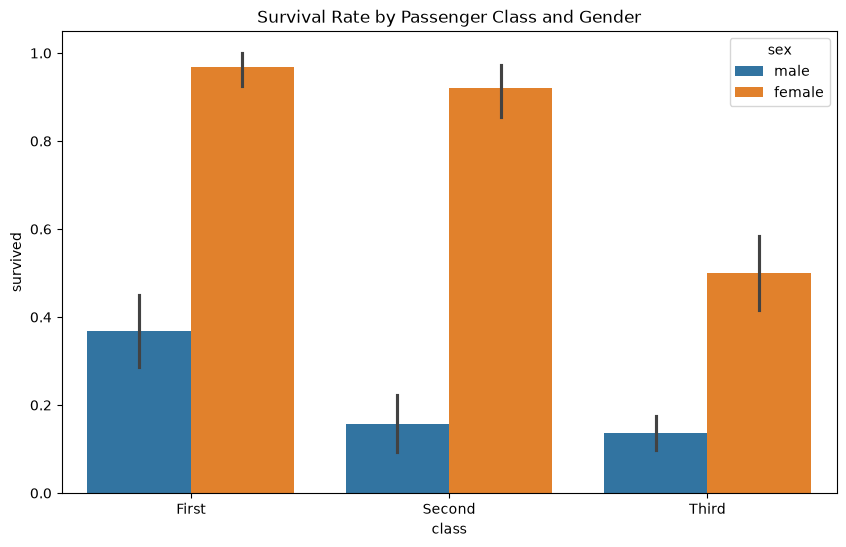

In [11]:
# histogram

plt.figure(figsize=(10, 6))
sns.barplot(data=df, x="class", y="survived", hue="sex")
plt.title("Survival Rate by Passenger Class and Gender")
plt.show()

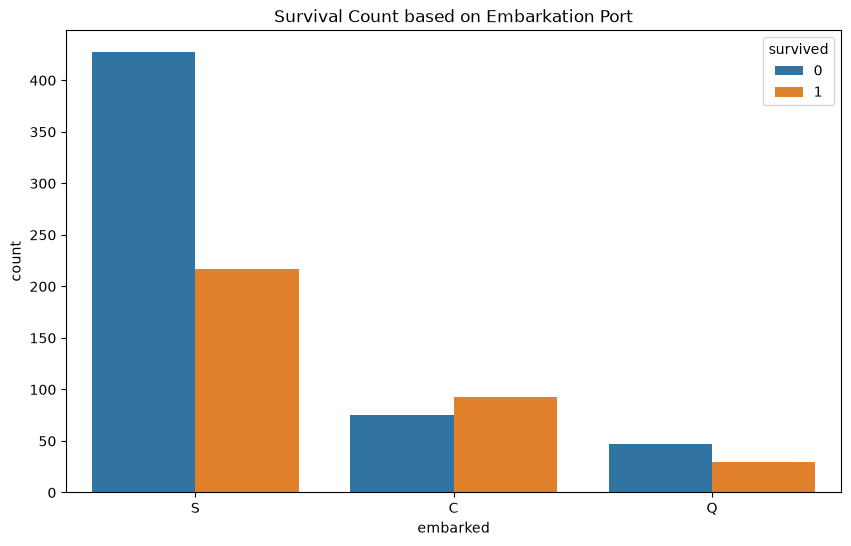

In [12]:
# plot counts

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="embarked", hue="survived")
plt.title("Survival Count based on Embarkation Port")
plt.show()

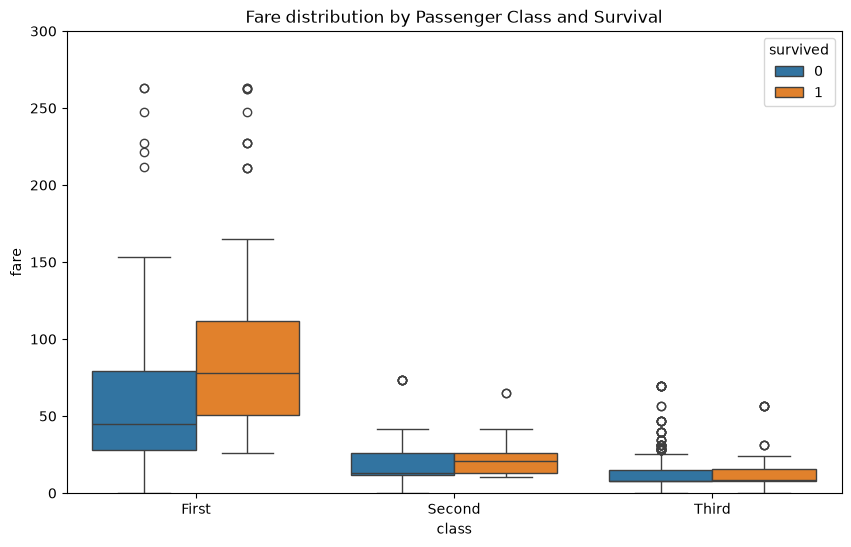

In [13]:
# perhaps your most important plot is boxplot! Take any numerical attribute and plot it along your class
# what do we see in a boxplot? are there any outliers? (univariate approach)

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="class", y="fare", hue="survived")
plt.ylim(0, 300)  # Limiting y-axis to 300 for better visualization
plt.title("Fare distribution by Passenger Class and Survival")
plt.show()

Text(0.5, 0, 'Fare')

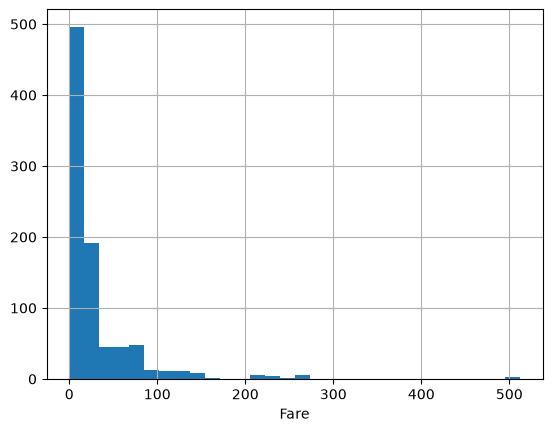

In [14]:
# do you see any potential outliers in fare attribute? (univariate approach)
df["fare"].hist(bins=30)
plt.xlabel("Fare")

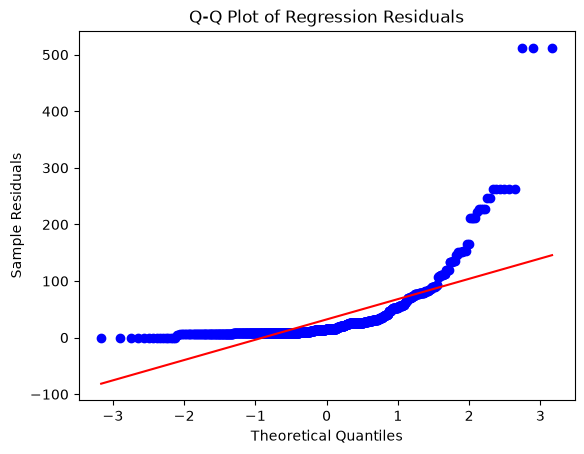

In [15]:
# Sanity check: Q-Q plot to check if fare deviates from a normal distribution (univariate approach)

stats.probplot(df["fare"].dropna(), dist="norm", plot=plt)
plt.title("Q-Q Plot of Regression Residuals")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Residuals")
plt.show()

In [16]:
# It looks like fare has outliers. Let's find them using IQR method (univariate approach)
# https://www.geeksforgeeks.org/blogs/anomaly-detection-techniques/

Q1 = percentile(df["fare"], 25, axis=0)
Q3 = percentile(df["fare"], 75, axis=0)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

anomalies = where((df["fare"] < lower_bound) | (df["fare"] > upper_bound))
unique_anomalies = unique(anomalies[0])
print("Anomalies detected at indices (IQR):", unique_anomalies)

# Homework: refactor the code to call all numerical columns, one by one

Anomalies detected at indices (IQR): [  1  27  31  34  52  61  62  72  88 102 118 120 124 139 151 159 180 195
 201 215 218 224 230 245 256 257 258 262 268 269 275 290 291 297 299 305
 306 307 310 311 318 319 324 325 332 334 336 337 341 366 369 373 375 377
 380 385 390 393 412 435 438 445 453 484 486 496 498 504 505 520 527 537
 540 544 550 557 558 581 585 587 591 609 627 641 645 655 659 660 665 679
 681 689 698 700 708 716 730 737 741 742 745 759 763 765 779 789 792 802
 820 829 835 846 849 856 863 879]


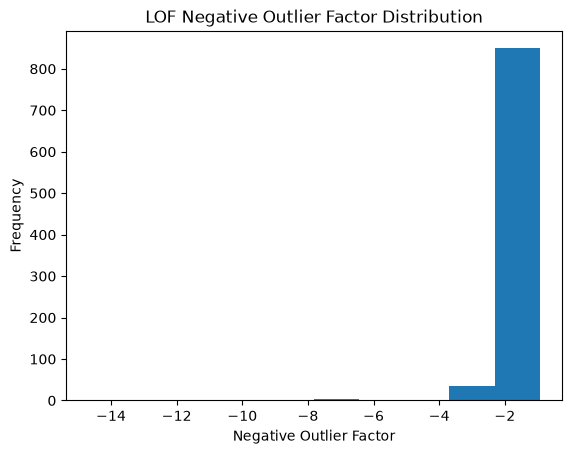

Strong anomalies detected at indices: [ 75 169 508 715 735 826]


In [17]:
# Let's calculate the outliners using Local Outlier Factor (multivariate approach)
# https://www.geeksforgeeks.org/machine-learning/local-outlier-factor/
# Since the algorithm is based on nearest neighbors, we need to scale the numerical data first

cat_cols = df.select_dtypes(exclude=["number"]).columns
num_cols = df.select_dtypes(include=["number"]).columns

cat_process = Pipeline([
    ("encode", preprocessing.OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ("impute", KNNImputer(keep_empty_features=True)),
])

num_process = Pipeline([
    ("impute", KNNImputer(keep_empty_features=True)),
    ("scale", preprocessing.RobustScaler())
])

preprocess = ColumnTransformer([
    ("cat_processes", cat_process, cat_cols),
    ("num_processes", num_process, num_cols),
])

LOF = Pipeline([
    ("prepare", preprocess),
    ("outliers", LocalOutlierFactor(n_jobs=-1)) # Needs OneHotEncoder. Also RobustScaler for numerical columns (num_cols)
])

# Fit and get LOF scores
LOF.fit_predict(df)

# negative_outlier_factor_ is a numpy array; convert to a pandas Series for plotting
Series(LOF.named_steps['outliers'].negative_outlier_factor_).plot(kind='hist')
plt.title("LOF Negative Outlier Factor Distribution")
plt.xlabel("Negative Outlier Factor")
plt.ylabel("Frequency")
plt.show()

lofIndices = where(LOF.named_steps["outliers"].negative_outlier_factor_ < -4)[0]
print("Strong anomalies detected at indices:", lofIndices)


In [18]:
# quick data aggregations using "groupby"

df.groupby("class")["age"].mean()

class
First     38.233441
Second    29.877630
Third     25.140620
Name: age, dtype: float64

In [19]:
# data preparation for classification: check for collinearity in input data

df[["survived", "alive"]].value_counts()

# Warning: Survived and Alive are proxy of each other

survived  alive
0         no       549
1         yes      342
Name: count, dtype: int64

In [20]:
# data preparation for classification (using "survived" as target variable)

X = df.drop(["survived", "alive"], axis=1)
y = df["survived"]

pipeline = Pipeline([
    ("encode", preprocessing.OneHotEncoder(sparse_output=False, handle_unknown='ignore')),   # encoding categorical attributes
    ("scaler", preprocessing.RobustScaler()), # MinMaxScaler(), PowerTransformer(), QuantileTransformer(), RobustScaler()
    ("classifier", ensemble.GradientBoostingClassifier(n_estimators=10)) # small number of estimators
])

cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3)
scores = cross_val_score(pipeline, X, y, cv=cv, n_jobs=-1, scoring='f1_macro')  # f1_macro for imbalanced classes
print("Classification accuracy values using 10-fold CV:", scores)   # any negative or extreme values?
print("Mean classification accuracy: %.4f" % scores.mean())

Classification accuracy values using 10-fold CV: [0.76800977 0.76075269 0.77634885 0.72775306 0.72372506 0.72901261
 0.81762295 0.82897265 0.84367681 0.82675195 0.72956731 0.7954023
 0.77162264 0.75549451 0.81391876 0.8322459  0.76306571 0.68283991
 0.81762295 0.74425287 0.82777474 0.76075269 0.78062926 0.81294662
 0.78733572 0.77162264 0.75915112 0.82897265 0.69101887 0.78450363]
Mean classification accuracy: 0.7771


In [21]:
# What are the top 5 features according to chi2 or f_classif? (SelectKBest)
# Make sure we have no missing values for univariate feature selection ...

In [22]:
# As you can see above, a few columns have missing values: age (float64), deck (category), and embark_town (object)
# we need to impute those missing values as we plan to use univariate feature selection, in other words,
# SelectKBest does not accept missing values encoded as NaN natively
# Have a look at https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

cat_cols = X.select_dtypes(exclude=["number"]).columns
num_cols = X.select_dtypes(include=["number"]).columns

cat_process = Pipeline([
    ("encode", preprocessing.OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ("impute", KNNImputer(keep_empty_features=True)),
])

num_process = Pipeline([
    ("impute", KNNImputer(keep_empty_features=True)),
    ("scale", preprocessing.RobustScaler())
])

preprocess = ColumnTransformer([
    ("cat_processes", cat_process, cat_cols),
    ("num_processes", num_process, num_cols)
])

mytop5 = Pipeline([
    ("prepare", preprocess),
    ("select", SelectKBest(score_func=f_classif, k=5))  # top 5 features using ANOVA F-value
])

mytop5.fit(X, y)
mytop5.named_steps["select"].get_feature_names_out()

array(['x0', 'x1', 'x10', 'x12', 'x13'], dtype=object)

In [23]:
# Univariate feature selection is okay as part of a pipeline (before your classifier/regressor)
# but it does not look good to print the selected features after one hot encoding ...

In [24]:
# let's try feature importance

model = Pipeline(steps=[
    ("encode", preprocessing.OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ("classifier", ensemble.GradientBoostingClassifier())
])

# Fit model
model.fit(X, y)

# Get feature importances
names = model.named_steps["encode"].get_feature_names_out()
importances = model.named_steps["classifier"].feature_importances_

# Print top 10 features
features = DataFrame({"Feature": names, "Importance": importances})
features = features.sort_values("Importance", ascending=False).reset_index(drop=True)
features.head(10)

,Feature,Importance
0,adult_male_False,0.201528
1,who_man,0.165742
2,adult_male_True,0.112345
3,class_Third,0.076129
4,pclass_3,0.068792
5,deck_nan,0.040031
6,fare_56.4958,0.020102
7,sex_male,0.014000
8,embark_town_Southampton,0.012171
9,pclass_1,0.009661


In [25]:
# Let's see what permutation importance says (another feature selection approach)
# code from https://scikit-learn.org/stable/auto_examples/inspection/plot_permutation_importance.html

# There's no need to impute values if we use this feature selection approach

pipeline.fit(X, y)
result = permutation_importance(
    pipeline, X, y, n_repeats=10, n_jobs=-1, scoring="f1_macro"
)

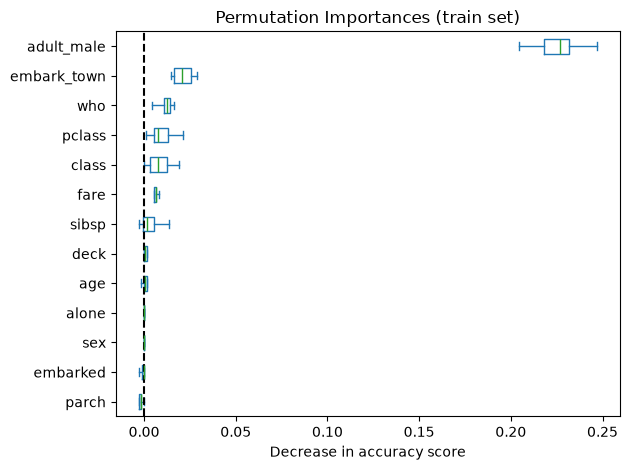

In [26]:
sorted_importances_idx = result.importances_mean.argsort()
importances = DataFrame(
    result.importances[sorted_importances_idx].T,
    columns=X.columns[sorted_importances_idx],
)
ax = importances.plot.box(vert=False, whis=10)
ax.set_title("Permutation Importances (train set)")
ax.axvline(x=0, color="k", linestyle="--")
ax.set_xlabel("Decrease in accuracy score")
ax.figure.tight_layout()

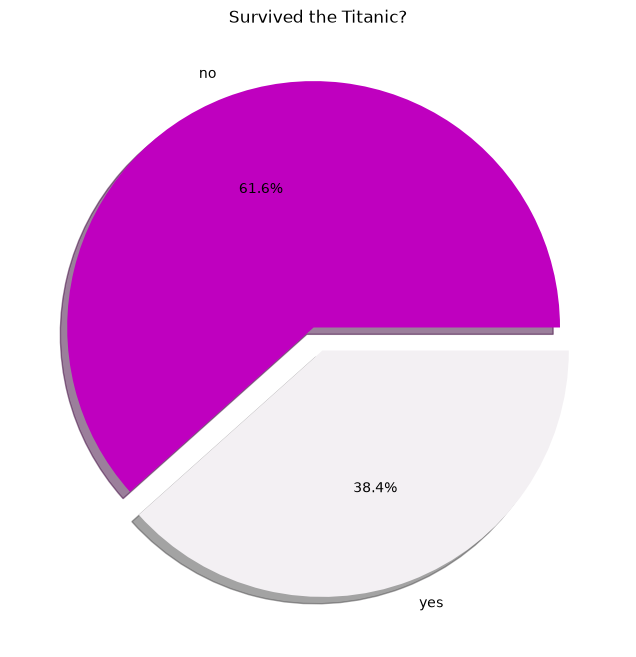

In [27]:
# Pie chart of target variable

plt.figure(figsize=(8,8))
df['alive'].value_counts().plot.pie(
        autopct='%1.1f%%',
        colors=sns.color_palette("light:m_r", n_colors=2),
        explode=[0.05]*df['alive'].nunique(),
        shadow=True
)
plt.ylabel('')
plt.title("Survived the Titanic?")
plt.show()